# Tugas Praktik Kelompok: Multi-Perspective Outlier Detection pada Data Penjualan Frozen Food

**Mata Kuliah:** Analisis Data Eksploratif & Deteksi Anomali (Presentasi Minggu ke-10 / Minggu ke-11)  
**Referensi Materi Kuliah:**  
1. **Week 5 -- Find Anomaly (`Week 5 - Find Anomaly.pptx`)**: Definisi Outlier menurut **Hawkins (1980)** (*observasi yang menyimpang jauh dari observasi lain sehingga menimbulkan kecurigaan bahwa ia dihasilkan oleh mekanisme yang berbeda*), Contoh Kasus *Purchasing Behavior* (pembeli yang datang sekali/jarang namun langsung memborong besar), Pendekatan Grafis (*Boxplot 1D*, *Scatter Plot 2D*), Pendekatan Statistik (*IQR*, *Mean +/- 3 SD*, *Median & MAD*), dan Penyebab Outlier (*Human Error*, *Instrument Error*, *Sampling Error*, *Data Manipulation*, *True Business Outlier*).  
2. **Week 7 -- Outlier Detection in Machine Learning (`Week 7 - OutlierDetection ML.ppt`)**: Pendekatan Grafis Multivariat (*Convex Hull*), *Distance-Based Outlier Detection* (**k-Nearest Neighbors / k-NN Distance**), *Density-Based Outlier Detection* (**Local Outlier Factor / LOF** untuk mengatasi masalah perbedaan kepadatan klaster $p_1$ vs $p_2$), dan *Clustering-Based Outlier Detection* (**K-Means Centroid Distance & Small Cluster**).

---

## Ringkasan Eksekutif & Struktur Pembahasan (3 Sisi Tugas)

Sesuai instruksi tugas praktik kelompok pada dataset **Penjualan Frozen Food (`Data Penjualan April - Sep 2020.xlsx` -> `bersih/penjualan_bersih.csv`, 1 April - 30 September 2020)**, kami mendefinisikan *abnormality* dan melakukan deteksi pencilan (*outlier detection*) dari **3 sisi utama** ditambah **1 tahap pra-pemrosesan pemisahan error**:

| Tahap / Sisi Analisis | Definisi *Abnormality* (Hasil Diskusi Kelompok) | Metode Statistik & ML yang Digunakan | Temuan Utama (Kuantitatif & Entitas) |
| :--- | :--- | :--- | :--- |
| **Tahap 0: Pemisahan Error Pencatatan vs Outlier Bisnis Sah** | Membedakan anomali akibat *human error* / mekanisme non-penjualan (sampling gratis) dari transaksi komersial sah. | Audit Katalog 20 Aturan (`R01`-`T02`), Imputasi *k-NN* berbasis $\log(1+\text{QTY})$, Deduplikasi. | Dari **6.779 baris mentah** -> **6.740 baris komersial bersih** (`38` baris sampling gratis dipisahkan; `20` baris `CASH` Rp 0 dipulihkan senilai **Rp 90,72 Juta**; `229` ejaan pelanggan dinormalisasi menjadi **180 outlet + `CASH`**). |
| **Sisi 1: Pelanggan yang Outlier** | **1A (Global Whale - $p_1$):** Pelanggan dengan total belanja (*Monetary*) atau frekuensi ekstrem.<br>**1B (One-Shot Bulk Buyer - $p_2$):** Pelanggan yang hanya datang 1-2 hari namun langsung memborong puluhan juta (nilai per kunjungan / `AOV` ekstrem).<br>**1C (Local Density - $p_3$):** Frekuensi tinggi eceran bernilai mikro atau belanja besar lalu *churn*. | - 1D Boxplot (`Q3 + 1.5 IQR` vs `Mean + 3 SD`)<br>- 2D Scatter & **Convex Hull**<br>- **k-NN Distance** ($k=5$)<br>- **Local Outlier Factor (LOF)** ($k=5$)<br>- **K-Means Clustering** ($K=4$) | - **Global Whale ($p_1$, > 3 SD):** `TOKO CITA RASA BARU` (**Rp 547,77 Jt**, F=50), `ADEK FROZEN` (**Rp 420,73 Jt**, F=11), `ANTON` (**Rp 311,76 Jt**), `HITE` (**Rp 229,86 Jt**), `AMANAH FROZEN` (**F=80 hari**).<br>- **One-Shot Bulk Buyer ($p_2$):** `PAK SUTARMUJI` (**F=2 hari, M=Rp 126,40 Jt, AOV=Rp 63,20 Jt/hari**, LOF=1,50), `MAS ROHMAT` (**F=2, AOV=Rp 27,51 Jt**), `YUDI` (**F=1, Rp 22,54 Jt**), `DEFRIADI` (**F=1, R=166, k-NN=#1 tertinggi 1,70**).<br>- **Local Density ($p_3$):** `KAK YENI` (**LOF=#1 tertinggi 1,61**), `OKE MART` (**LOF=1,55**), `FADIL ANAK BOS` (**F=26, AOV Rp 180rb**). |
| **Sisi 2: Harga Barang yang Outlier (Dilihat dari $X$)** | Harga terlalu murah atau terlalu mahal tidak bisa dinilai tanpa konteks $X$. Kami menguji **3 Konteks $X$**:<br>- $X_1 =$ **SKU + Satuan Kemasan**<br>- $X_2 =$ **Kuantitas (`QTY`) & Harga Efektif (`OMZET/QTY`)**<br>- $X_3 =$ **Kategori Satuan Kemasan (`DUS`..`PCS`)** | - Deviasi Relatif terhadap Median ($X_1$: pagar $\pm 30\%$)<br>- Skor-Z Robust berbasis MAD ($|Z_{\text{robust}}| > 5$)<br>- Audit Diskon Aritmetika ($X_2$)<br>- Boxplot Lintas Kemasan ($X_3$) | - **Terlalu Murah ($X_1$ & $X_2$):** `LUTOSA-001` (`PACK`) dijual **Rp 15.000 vs Median Rp 26.000 (-42,3%)** ke `FADIL ANAK BOS` (3x); `DEN-002` (`PACK`) **Rp 4.000 vs Rp 6.000 (-33,3%)**; Diskon tak wajar **-50%** (`A02`) pada `MIT-005` & `MIT-013` untuk `PAK ERWIN` (4x).<br>- **Terlalu Mahal ($X_1$):** `CONE-004` (`BKS`) **Rp 7.000 vs Rp 5.000 (+40,0%)**; `DEN-011` (`PACK`) **Rp 6.000 vs Rp 4.500 (+33,3%)**; `SHIF-003` (`DUS`) **Rp 262.500 vs Rp 201.020 (+30,6%)**.<br>- **Konteks Satuan ($X_3$):** 56 transaksi `DUS` melampaui pagar `Rp 573.000` (keju impor `EURIAL-001` Rp 960rb-1 Jt/DUS). |
| **Sisi 3: Transaksi yang Outlier** | **3A (Level Baris Item):** Transaksi dengan `OMZET` atau `QTY` ekstrem per baris.<br>**3B (Level Struk/Keranjang Harian):** Kombinasi `TGL + PELANGGAN` dengan total belanja atau variasi SKU ekstrem.<br>**3C (Level Temporal & Operasional):** Hari lonjakan omzet ekstrem & transaksi di luar hari operasional. | - Pagar **Log-IQR** ($1,5\times$ dan $3,0\times$ IQR pada $\log_{10}(\text{OMZET})$)<br>- Skor-Z Robust `QTY` per SKU ($Z_{\text{robust}} > 8$)<br>- **LOF & k-NN** pada 1.495 Keranjang Struk<br>- Time-Series $Z_{\text{robust}}$ Harian & Audit Hari Kerja | - **Level Baris (`N=6.740`):** **208 baris** > Pagar $1,5\times\text{Log-IQR}$ (Rp 5,62 Jt); **2 baris** > Pagar Ekstrem $3,0\times\text{Log-IQR}$ (Rp 54,91 Jt) yaitu `PAK SUTARMUJI` memborong **200 DUS `MIN-001` senilai Rp 63,20 Juta/baris** (3 & 13 Agu); Rekor kuantitas **400 PACK `BAK-002`** oleh `ANTON`.<br>- **Level Struk (`N=1.495`):** Terpisah menjadi *Single-SKU Mega-Order* (`PAK SUTARMUJI` 1 item = Rp 63,2 Jt) vs *Multi-SKU Hyper-Basket* (`ADEK FROZEN` 26-39 item/hari = Rp 45,7-58,8 Jt).<br>- **Level Temporal:** **4 hari lonjakan ekstrem** (puncak **26 Juni: Rp 188,49 Jt**) & **1 transaksi Hari Minggu** (`30 Agustus 2020`, `PAK PEPI`, Rp 180.000) padahal 25 dari 26 hari Minggu toko tutup. |

## Format Visualisasi Data: Grafik Mandiri (*Raw Graphs*) dengan Legenda Lengkap

Sesuai kebutuhan presentasi PowerPoint mandiri, seluruh grafik di bawah ini disajikan dalam format **Grafik Mandiri (*Raw Plots*)**:
1. **Area Plot Murni & Bersih**: Kanvas fokus sepenuhnya pada data (titik scatter, garis fluktuasi, batang bar, kotak boxplot, dan poligon convex hull) dengan grid halus dan label sumbu berformat Rupiah/Kuantitas asli.
2. **Dilengkapi Kotak Legenda Lengkap (*Self-Contained Legend Box*)**: Setiap grafik menyertakan kotak legenda di sisi kanan yang menjelaskan makna warna simbol, bentuk penanda (*marker shape*), garis batas ambang (*dashed thresholds*), dan zona klaster.
3. **Bebas dari Kartu Komentar Padat**: Tidak ada teks narasi panjang yang menempel pada badan grafik, sehingga grafik dapat langsung disalin ke PowerPoint dan dikombinasikan dengan poin-poin presentasi Anda sendiri.
4. **Tersedia File Gambar Resolusi Tinggi**: File PNG beresolusi tinggi (1500 x 850/900 px) tersimpan rapi di direktori `slide_assets/outlier_ppt/raw/`.

---
## Tahap 0: Pra-Pemrosesan & Pemisahan *Data Error* vs *Outlier Bisnis Sah*

Mengacu pada **Slide 3 & Slide 10 (`Week 5 - Find Anomaly.pptx`)**, langkah paling krusial sebelum menjalankan algoritma deteksi outlier adalah memastikan bahwa pencilan yang dianalisis bukan sekadar *garbage-in* akibat kesalahan ketik atau inkonsistensi master data:
- **Normalisasi Entitas Pelanggan (`R03`)**: 229 penulisan nama pelanggan dinormalisasi menjadi **180 outlet kanonik** + agregat `CASH`.
- **Pemisahan Mekanisme Non-Penjualan (`K03b` & `K05`)**: 38 baris pengeluaran sampel promosi gratis (`SAMPEL CRB`, `SAMPLING MITRAKU`) dipisahkan dari transaksi penjualan.
- **Pemulihan *Human Error* Harga Kosong (`K03a`)**: 20 baris transaksi `CASH` berkuantitas besar (hingga 106 DUS) yang tertulis Rp 0 dipulihkan via *k-NN* berbasis $\log(1+\text{QTY})$ (+Rp 90,72 Juta omzet).

Total Transaksi Komersial Bersih : 6,740 baris
Rentang Waktu Transaksi          : 2020-04-01 s.d. 2020-09-30 (143 hari aktif)
Jumlah SKU Kanonik Unik          : 268 SKU (7 satuan kemasan)
Jumlah Pelanggan Outlet Bernama  : 180 outlet (+ 1 agregat walk-in CASH = 181 entitas)
Total Omzet Bersih (6 Bulan)     : Rp 4,621,049,783

ID,Kategori,Keparahan,Deskripsi Aturan,Baris,%
R01,Integritas Referensial,Peringatan,Satu kode barang memiliki lebih dari satu ejaan nama barang di data mentah,533,7.86%
R03,Integritas Referensial,Info,Satu pelanggan/outlet tercatat di bawah lebih dari satu kode kanal,402,5.93%
T01,Temporal Operasional,Info,Tanggal transaksi dengan lonjakan omzet harian ekstrem (Z_robust > 5.0),370,5.46%
S03,Pencilan Statistik,Info,Kuantitas pembelian (QTY) sangat besar secara statistik untuk barang tersebut (Z_robust > 8),237,3.50%
R02,Integritas Referensial,Peringatan,Satu nama barang digunakan oleh lebih dari satu kode barang berbeda (ARTHUR vs LUTOSA),172,2.54%
D01,Duplikasi,Peringatan,Baris transaksi duplikat identik persis pada seluruh kolom,73,1.08%
A01,Aritmetika,Peringatan,Selisih nilai JUMLAH terhadap QTY x HARGA akibat diskon/pembulatan wajar (rasio 85%-97%),73,1.08%
K03b,Kelengkapan,Kritis,HARGA dan JUMLAH bernilai nol pada pengeluaran sampel/promosi (dipisahkan),38,0.56%
S02,Pencilan Statistik,Peringatan,Harga satuan menyimpang secara statistik terhadap median barang+satuan (|Z_robust| > 5),26,0.38%
K03a,Kelengkapan,Kritis,HARGA dan JUMLAH kosong pada transaksi penjualan tunai (CASH) berkuantitas besar (dipulihkan),20,0.30%


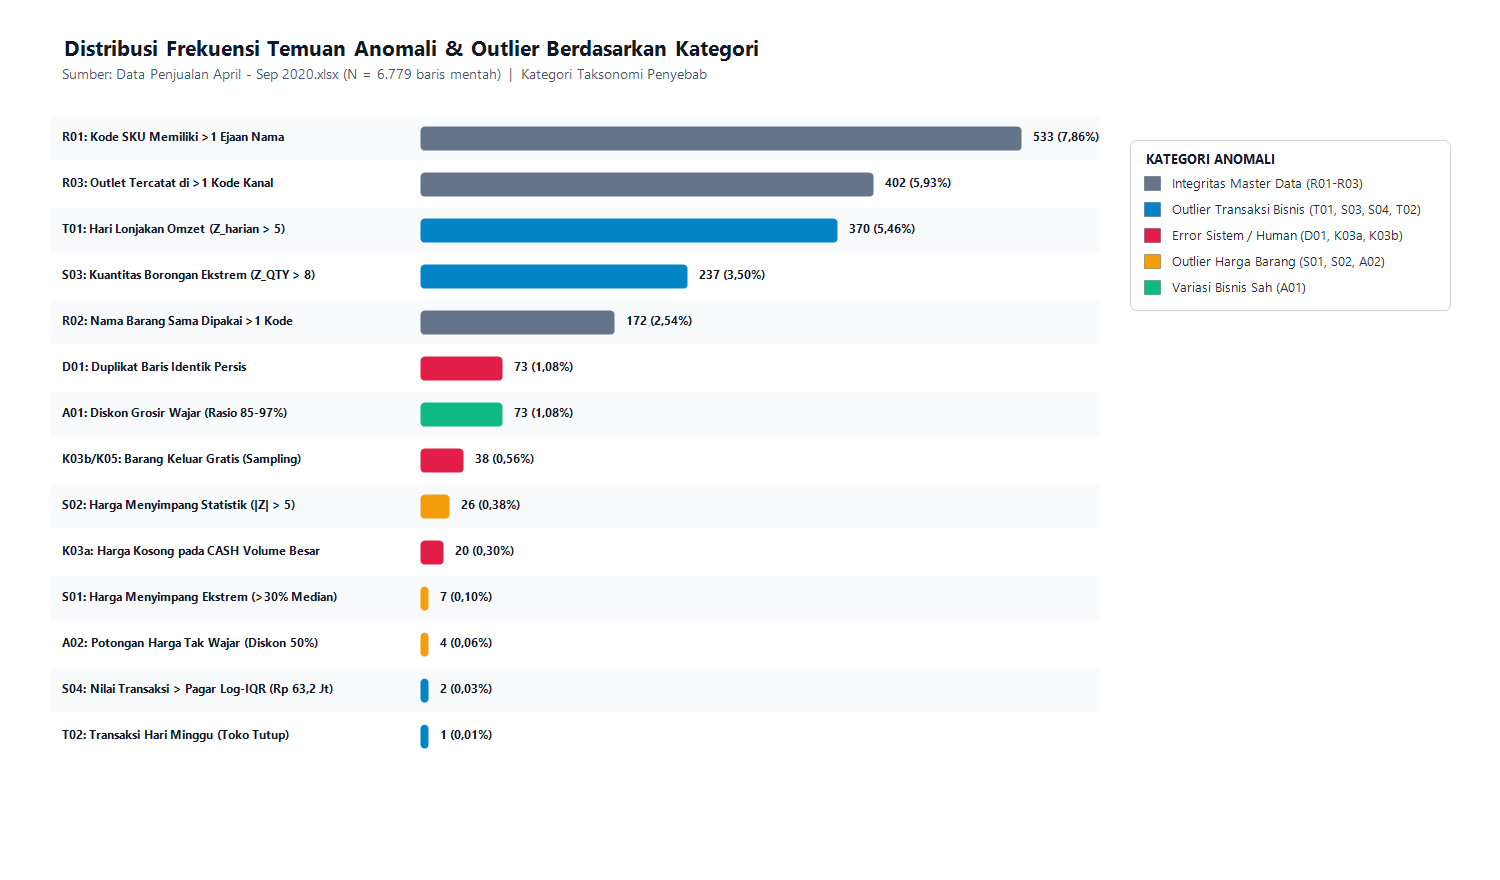

In [1]:
import warnings
warnings.filterwarnings('ignore')
import pandas as pd
import numpy as np
from IPython.display import display, Image

# 1. Memuat data bersih hasil pipeline normalisasi & katalog log anomali
df_clean = pd.read_csv('bersih/penjualan_bersih.csv', parse_dates=['TGL'])
df_lrfm  = pd.read_csv('bersih/lrfm_pelanggan.csv')
df_rules = pd.read_csv('bersih/katalog_aturan.csv')

print(f'Total Transaksi Komersial Bersih : {len(df_clean):,} baris')
print(f'Rentang Waktu Transaksi          : {df_clean["TGL"].min().date()} s.d. {df_clean["TGL"].max().date()} ({df_clean["TGL"].nunique()} hari aktif)')
print(f'Jumlah SKU Kanonik Unik          : {df_clean["KODE"].nunique()} SKU ({df_clean["SATUAN"].nunique()} satuan kemasan)')
print(f'Jumlah Pelanggan Outlet Bernama  : {len(df_lrfm)} outlet (+ 1 agregat walk-in CASH = {df_clean["PELANGGAN"].nunique()} entitas)')
print(f'Total Omzet Bersih (6 Bulan)     : Rp {df_clean["OMZET"].sum():,.0f}')

# Menampilkan tabel aturan dan grafik raw frekuensi anomali dengan legenda
display(df_rules[['id_aturan', 'kategori', 'tingkat_keparahan', 'deskripsi_aturan', 'jumlah_baris_terdampak', 'persentase_baris']].head(14))
display(Image(filename='slide_assets/outlier_ppt/raw/raw_01_frekuensi_aturan_anomali.png'))

---
## Sisi 1: Menemukan Pelanggan yang Outlier (*Customer Outlier Detection*)

### 1.1 Definisi *Abnormality* Pelanggan (Hasil Diskusi Kelompok)
Kami membagi ketidaknormalan pelanggan menjadi 3 arketipe:
1. **Tipe $p_1$ -- Global Whale Outliers:** Pelanggan dengan total omzet ($M$) atau hari kedatangan ($F$) melampaui `Mean + 3*SD` ($M > \text{Rp } 215,79\text{ Jt}$ atau $F > 40,3\text{ hari}$) serta membentuk sudut Convex Hull terluar.
2. **Tipe $p_2$ -- One-Shot / Rare Bulk Buyers:** Pelanggan yang hanya datang 1-2 hari ($F \le 2$), namun langsung memborong puluhan juta sehingga **AOV ($M/F$) melampaui pagar `Mean + 3*SD` (Rp 22,68 Jt/hari)**. Kasus ini sesuai dengan contoh purchasing dosen di **Week 5 Slide 4**.
3. **Tipe $p_3$ -- Local Density Outliers:** Pelanggan dengan nilai LOF tertinggi di ruang multidimensi LRFM karena terisolasi secara lokal.

Hasil Deteksi Outlier Univariat (N = 180 Pelanggan Bernama):
- Monetary > Q3 + 1.5*IQR (Rp 41,934,750) : 19 pelanggan (4 di antaranya > Mean + 3*SD Rp 215,790,010)
- Frequency > Q3 + 1.5*IQR (17.0 hari)    : 17 pelanggan (5 di antaranya > Mean + 3*SD 40.30 hari)
- AOV (M/F) > Q3 + 1.5*IQR (Rp 6,478,506) : 18 pelanggan (3 di antaranya > Mean + 3*SD Rp 22,676,811)

Metrik,Mean,SD,Median,IQR,Pagar 1.5*IQR,Outlier IQR,Pagar 3*SD,Outlier 3*SD
Monetary (Rp),"24,742,209","63,682,600","5,989,200","15,820,500","41,934,750",19,"215,790,010",4
Frequency (Hari),7.71,10.86,4.00,6.00,17.00,17,40.30,5
AOV = M/F (Rp/Hari),"3,261,454","6,471,786","1,622,000","2,292,290","6,478,506",18,"22,676,811",3
Recency (Hari),44.58,46.98,23.50,65.25,170.13,2,185.51,0


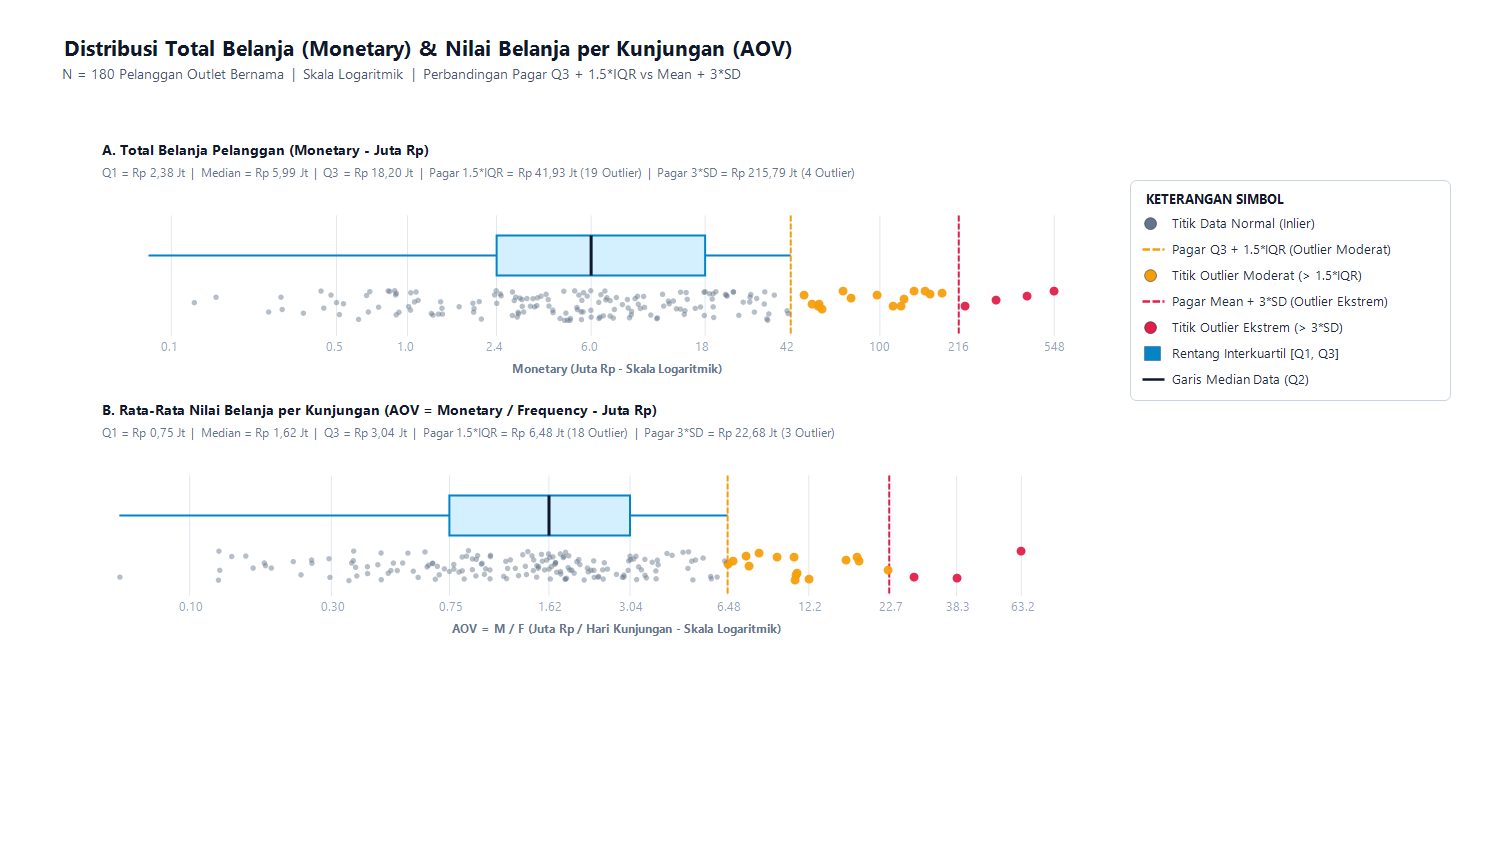

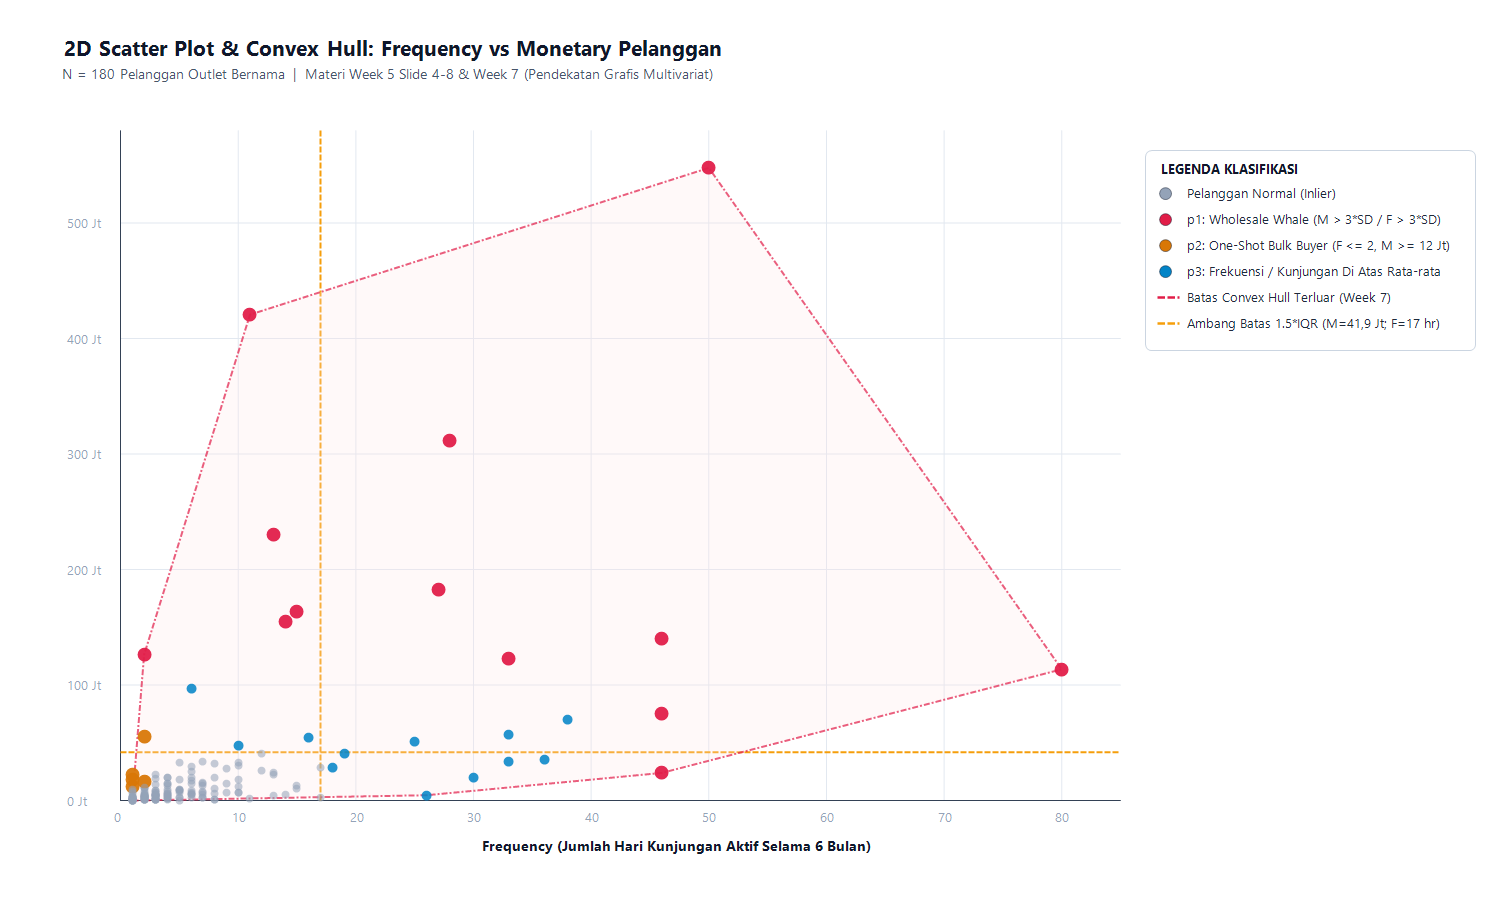

In [2]:
# SISI 1A: Deteksi Outlier Pelanggan secara Statistik Deskriptif & Grafis (Boxplot 1D & Convex Hull 2D)
cust = df_lrfm.copy()
cust['AOV'] = cust['M'] / cust['F']

# Menghitung batas IQR dan 3-Sigma untuk Monetary (M), Frequency (F), dan AOV (M/F)
stats_rows = []
for col, label in [('M', 'Monetary (Rp)'), ('F', 'Frequency (Hari)'), ('AOV', 'AOV = M/F (Rp/Hari)'), ('R', 'Recency (Hari)')]:
    q1, med, q3 = cust[col].quantile([0.25, 0.50, 0.75])
    iqr = q3 - q1
    fence_iqr = q3 + 1.5 * iqr
    fence_3sd = cust[col].mean() + 3.0 * cust[col].std()
    stats_rows.append({
        'Metrik': label,
        'Mean': cust[col].mean(), 'SD': cust[col].std(),
        'Median': med, 'IQR': iqr,
        'Pagar_1.5_IQR': fence_iqr, 'N_Outlier_IQR': int((cust[col] > fence_iqr).sum()),
        'Pagar_3_SD': fence_3sd, 'N_Outlier_3SD': int((cust[col] > fence_3sd).sum())
    })
df_stat_cust = pd.DataFrame(stats_rows)
display(df_stat_cust)

# Menampilkan 2 Grafik Raw: Boxplot 1D & 2D Scatter + Convex Hull (dengan Legenda Mandiri)
display(Image(filename='slide_assets/outlier_ppt/raw/raw_02_pelanggan_boxplot_monetary_aov.png'))
display(Image(filename='slide_assets/outlier_ppt/raw/raw_03_pelanggan_scatter_convexhull.png'))

### 1.2 Deteksi Outlier Pelanggan Multivariat dengan Machine Learning (Week 7)
Menerapkan algoritma **k-NN Distance ($k=5$)**, **Local Outlier Factor / LOF ($k=5$)**, dan **Convex Hull** untuk menangkap pelanggan abnormal yang memiliki kepadatan lokal berbeda:
- **k-NN Distance Terbesar:** `DEFRIADI` (1,701), `PAK SUTARMUJI` (1,667), `KAK YENI` (1,657).
- **LOF Terbesar:** `KAK YENI` (1,609), `OKE MART` (1,545), `PAK SUTARMUJI` (1,495), `DEFRIADI` (1,454).

Top 12 Pelanggan Outlier Berdasarkan Konsensus Statistik & Machine Learning:
1. TOKO CITA RASA BARU | F=50 | M=Rp 547.77 Jt | AOV=Rp 10.96 Jt | LOF=1.340
2. PAK SUTARMUJI       | F=2  | M=Rp 126.40 Jt | AOV=Rp 63.20 Jt | LOF=1.495
3. ADEK FROZEN         | F=11 | M=Rp 420.73 Jt | AOV=Rp 38.25 Jt | LOF=1.181
4. DEFRIADI            | F=1  | M=Rp 12.15 Jt  | AOV=Rp 12.15 Jt | LOF=1.454
5. KAK YENI            | F=5  | M=Rp 0.29 Jt   | AOV=Rp 0.06 Jt  | LOF=1.609

No,Nama Pelanggan,L (Hari),R (Hari),F (Hari),Monetary (Rp),AOV = M/F (Rp),k-NN Dist,LOF Score,Convex Hull,Tipe Outlier & Diagnosis Kelompok
1,TOKO CITA RASA BARU,173,2,50,"547,770,564","10,955,411",1.233,1.340,Ya,p1 (Whale #1): Omzet & Frekuensi > 3 SD
2,PAK SUTARMUJI,10,48,2,"126,400,000","63,200,000",1.667,1.495,Ya,"p2 (Bulk Buyer #1): Hanya 2x datang, sekali beli Rp 63,2 Jt!"
3,ADEK FROZEN,97,10,11,"420,733,900","38,248,536",1.236,1.181,Ya,p1 (Whale #2): Omzet #2 & AOV #2 (> 3 SD)
4,DEFRIADI,0,166,1,"12,150,000","12,150,000",1.701,1.454,Tidak,"p2 (One-Shot Churn): k-NN #1 tertinggi; beli 1x Rp 12,15 Jt lalu berhenti"
5,KAK YENI,40,136,5,"290,000","58,000",1.657,1.609,Tidak,p3 (Local Density #1): LOF tertinggi; nilai mikro terisolasi
6,ANTON,173,0,28,"311,763,500","11,134,411",0.950,1.150,Tidak,"p1 (Whale #3): Omzet > 3 SD, pemborong 400 PACK Bakso Mie"
7,HITE,87,36,13,"229,858,600","17,681,431",0.920,1.140,Tidak,p1 (Whale #4): Omzet > 3 SD & AOV > 1.5 IQR
8,MAS ROHMAT,38,20,2,"55,020,000","27,510,000",1.052,1.246,Tidak,"p2 (Bulk Buyer #2): Hanya 2x datang, AOV > 3 SD (Rp 27,51 Jt)"
9,AMANAH FROZEN,175,2,80,"113,727,250","1,421,591",0.996,1.219,Ya,p1 (Frequency #1): Datang 80 hari aktif (> 7 SD di atas rata-rata!)
10,OKE MART,22,117,3,"18,988,000","6,329,333",1.139,1.545,Tidak,p2 (LOF #3): Belanja 3x besar di awal lalu churn mendadak


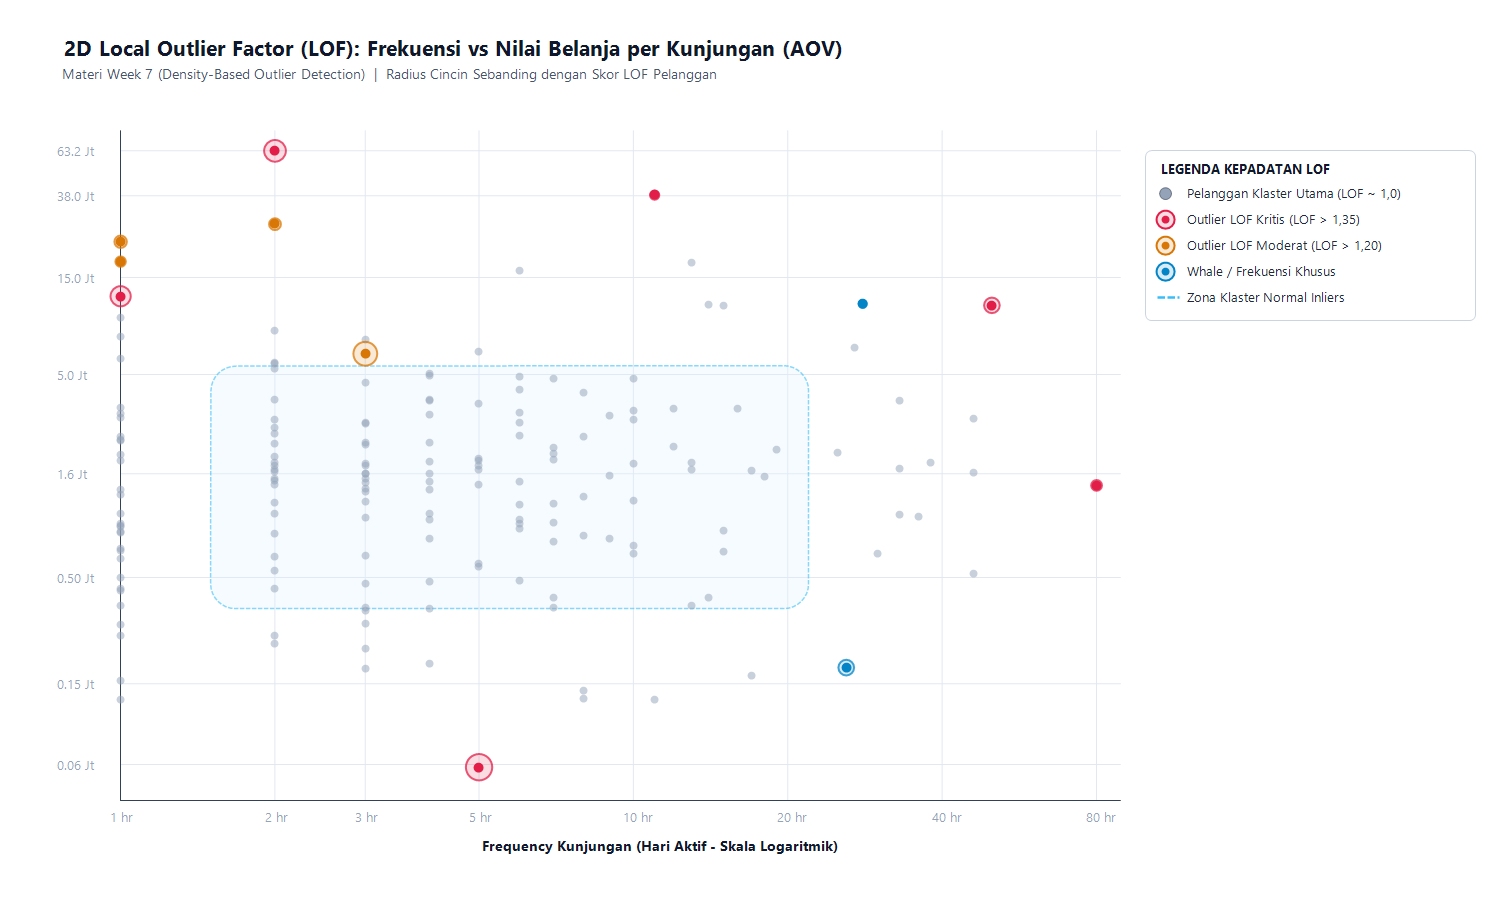

In [3]:
from sklearn.neighbors import NearestNeighbors, LocalOutlierFactor
from sklearn.preprocessing import StandardScaler
from scipy.spatial import ConvexHull

# Ruang fitur multivariat pelanggan: [log10(F), log10(M), log10(AOV), R, L]
X_raw = np.column_stack([
    np.log10(cust['F']),
    np.log10(cust['M']),
    np.log10(cust['AOV']),
    cust['R'],
    cust['L']
])
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_raw)

# 1. Distance-Based: k-NN Average Distance (k = 5)
nn = NearestNeighbors(n_neighbors=6)
nn.fit(X_scaled)
dists, _ = nn.kneighbors(X_scaled)
cust['kNN_Dist'] = dists[:, 1:].mean(axis=1)

# 2. Density-Based: Local Outlier Factor / LOF (k = 5)
lof = LocalOutlierFactor(n_neighbors=5)
lof.fit_predict(X_scaled)
cust['LOF_Score'] = -lof.negative_outlier_factor_

# 3. Convex Hull pada ruang 2D (Frequency vs Monetary)
hull = ConvexHull(cust[['F', 'M']].values)
cust['Is_ConvexHull'] = False
cust.loc[hull.vertices, 'Is_ConvexHull'] = True

# Menampilkan tabel top 12 outlier dan grafik raw LOF Density Map
top_cust = cust.sort_values(by=['LOF_Score', 'M'], ascending=False).head(12)
display(top_cust[['PELANGGAN', 'F', 'M', 'AOV', 'R', 'kNN_Dist', 'LOF_Score', 'Is_ConvexHull']])
display(Image(filename='slide_assets/outlier_ppt/raw/raw_04_pelanggan_lof_density.png'))

---
## Sisi 2: Menemukan Harga Barang yang Outlier (*Terlalu Murah atau Terlalu Mahal Bila Dilihat dari $X$*)

Kami menguji harga outlier melalui 3 konteks pembanding $X$:
1. **$X_1 =$ SKU + Satuan Kemasan yang Sama (`KODE + SATUAN`):** Deviasi terhadap median SKU+Satuan di luar ambang batas $\pm 30\%$ (`S01`).
2. **$X_2 =$ Kuantitas (`QTY`) & Diskon Aritmetika (`OMZET / QTY`):** Membedakan tier grosir wajar (`A01`: diskon 3%-15%) vs potongan harga ekstrem tidak wajar (`A02`: diskon -50% pada Pak Erwin).
3. **$X_3 =$ Kategori Satuan Kemasan (`DUS`..`PCS`):** Menemukan 56 baris transaksi keju impor `EURIAL-001` (Rp 880rb-1 Jt/DUS) yang melampaui pagar atas satuan DUS (Rp 573.000).

Jumlah Transaksi Outlier Harga Kritis (|Deviasi| > 30% terhadap Median SKU+Satuan): 11 baris

Baris Asal,Tanggal,Pelanggan,Kode SKU,Nama Barang,Satuan,QTY,Harga Nota,Harga Efektif,Median X1,Deviasi (%),Diagnosis Outlier Harga (Dilihat dari X)
2325,2020-06-05,PAK ERWIN,MIT-005,MITRAKU NUGGET STICK 500 GR,PACK,11,"28,900","14,450","28,900",-50.0%,Terlalu Murah (X2 - A02): Tagihan dipotong 50% dari QTY x HARGA
2334,2020-06-06,PAK ERWIN,MIT-005,MITRAKU NUGGET STICK 500 GR,PACK,6,"28,900","14,450","28,900",-50.0%,Terlalu Murah (X2 - A02): Tagihan dipotong 50% dari QTY x HARGA
4559,2020-08-03,PAK ERWIN,MIT-005,MITRAKU NUGGET STICK 500 GR,PACK,27,"28,900","14,450","28,900",-50.0%,Terlalu Murah (X2 - A02): Tagihan dipotong 50% dari QTY x HARGA
4560,2020-08-03,PAK ERWIN,MIT-013,MITRAKU OTAK - OTAK IKAN 200 GR,PACK,51,"9,900","4,950","9,900",-50.0%,Terlalu Murah (X2 - A02): Tagihan dipotong 50% dari QTY x HARGA
1030,2020-04-28,FADIL ANAK BOS,LUTOSA-001,"KENTANG LUTOSA STRAIGHT CUT 2,5 KG",PACK,2,"15,000","15,000","26,000",-42.3%,"Terlalu Murah (X1 - S01): Di bawah HPP kentang 2,5 kg (QTY kecil 2 PACK)"
2215,2020-06-03,FADIL ANAK BOS,LUTOSA-001,"KENTANG LUTOSA STRAIGHT CUT 2,5 KG",PACK,1,"15,000","15,000","26,000",-42.3%,"Terlalu Murah (X1 - S01): Di bawah HPP kentang 2,5 kg (QTY kecil 1 PACK)"
2826,2020-06-19,FADIL ANAK BOS,LUTOSA-001,"KENTANG LUTOSA STRAIGHT CUT 2,5 KG",PACK,2,"15,000","15,000","26,000",-42.3%,Terlalu Murah (X1 - S01): Harga miring berulang khusus Fadil Anak Bos
2106,2020-05-30,TOKO CITA RASA BARU,DEN-002,SOSIS SAPI DEN FOOD MERAH ISI 6,PACK,27,"4,000","4,000","6,000",-33.3%,Terlalu Murah (X1 - S01): Diskon ekstrem / cuci stok pelanggan Whale #1
6165,2020-09-14,ANJANI FROZEN FOOD,SHIF-003,SHIFUDO OTAK - OTAK SINGAPORE 500 GR,DUS,2,"262,500","262,500","201,020",+30.6%,Terlalu Mahal (X1 - S01): Salah pakai harga SKU lain / lonjakan ekstrem
4098,2020-07-21,CASH,DEN-011,BAKSO SAPI DEN FOOD 150 GR ISI 15,PACK,6,"6,000","6,000","4,500",+33.3%,"Terlalu Mahal (X1 - S01): Markup harga eceran walk-in CASH (+33,3%)"


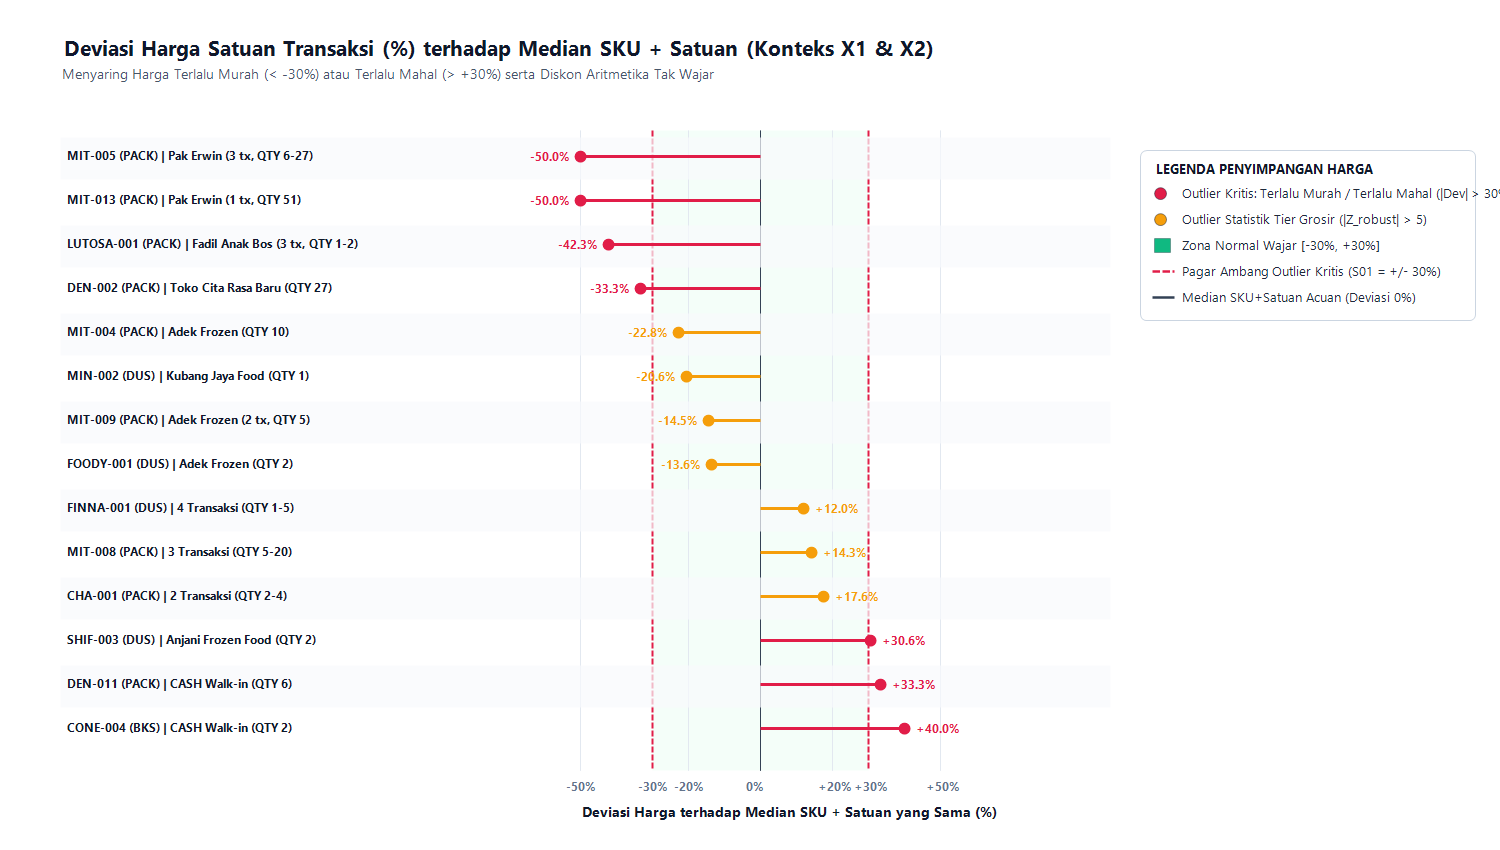

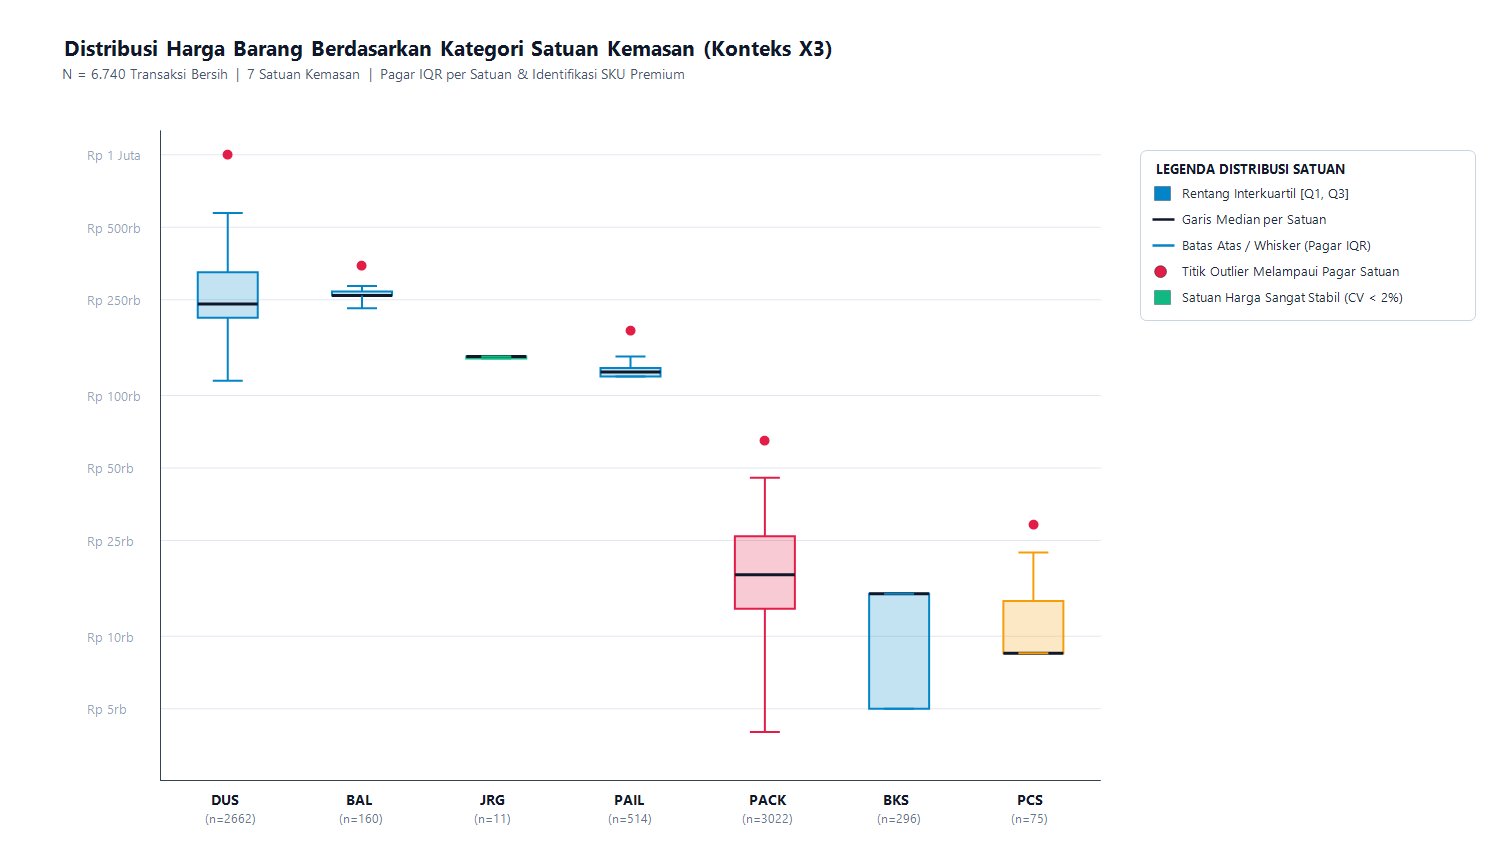

In [4]:
# SISI 2: Deteksi Harga Barang yang Outlier Dilihat dari Konteks X1, X2, dan X3
df_clean['HARGA_EFEKTIF'] = df_clean['OMZET'] / df_clean['QTY']

# Menghitung Median per X1 = (KODE, SATUAN)
grp_x1 = df_clean.groupby(['KODE', 'SATUAN'])['HARGA']
med_x1 = grp_x1.transform('median')
df_clean['MEDIAN_X1'] = med_x1
df_clean['DEV_PCT_X1'] = (df_clean['HARGA'] - med_x1) / med_x1 * 100.0
df_clean['DEV_EFEKTIF_PCT'] = (df_clean['HARGA_EFEKTIF'] - med_x1) / med_x1 * 100.0

outlier_harga_kritis = df_clean[
    (df_clean['DEV_PCT_X1'].abs() > 30.0) | (df_clean['DEV_EFEKTIF_PCT'].abs() > 30.0)
][['TGL', 'PELANGGAN', 'KODE', 'NAMA_BARANG', 'SATUAN', 'QTY', 'HARGA', 'HARGA_EFEKTIF', 'MEDIAN_X1', 'DEV_EFEKTIF_PCT', 'ATURAN_TERPICU']]

display(outlier_harga_kritis.sort_values('DEV_EFEKTIF_PCT'))

# Menampilkan 2 Grafik Raw: Diverging Lollipop & Boxplot Kemasan (dengan Legenda Mandiri)
display(Image(filename='slide_assets/outlier_ppt/raw/raw_05_harga_diverging_sku_median.png'))
display(Image(filename='slide_assets/outlier_ppt/raw/raw_06_harga_distribusi_satuan_kemasan.png'))

---
## Sisi 3: Menemukan Transaksi yang Outlier (*Transaction Outlier Detection*)

### 3.1 Level Baris Item & Level Keranjang Struk
- **Level Baris Item ($N = 6.740$):** 208 baris > Pagar Log-IQR (Rp 5,62 Jt) dan 2 baris mega-outlier `S04` (> Rp 54,9 Jt) milik `PAK SUTARMUJI` (2x Rp 63,20 Jt/baris). Kuantitas terbesar: 400 PACK Bakso Mie milik `ANTON`.
- **Level Keranjang Struk Harian ($N = 1.495$):** 34 struk > 3*SD (Rp 21,5 Jt), terpecah menjadi *Single-SKU Mega-Order* (`PAK SUTARMUJI` 1 item Rp 63,2 Jt) vs *Multi-SKU Hyper-Basket* (`ADEK FROZEN` 26-39 item Rp 45,7-58,8 Jt).

Pagar Log-IQR 1.5x : Rp 5,623,413 -> 208 baris outlier
Pagar Log-IQR 3.0x : Rp 54,907,061 -> 2 baris outlier ekstrem (S04)

Peringkat,Tanggal,Pelanggan,Kode SKU,Nama Barang,Satuan,QTY,Harga Satuan,Nilai Transaksi (OMZET),Tipe Outlier Transaksi
1,2020-08-03,PAK SUTARMUJI,MIN-001,MINAKU OTAK - OTAK 500 GR X 20 PACK,DUS,200,"316,000","Rp 63,200,000","S04 (#1): Melampaui Pagar 3.0 x Log-IQR (>Rp 54,9 Jt)"
2,2020-08-13,PAK SUTARMUJI,MIN-001,MINAKU OTAK - OTAK 500 GR X 20 PACK,DUS,200,"316,000","Rp 63,200,000","S04 (#2): Melampaui Pagar 3.0 x Log-IQR (>Rp 54,9 Jt)"
3,2020-08-03,MAS ROHMAT,MIN-001,MINAKU OTAK - OTAK 500 GR X 20 PACK,DUS,150,"305,000","Rp 45,750,000","Mega-Order #3: Borongan 150 DUS (99,5x lipat median!)"
4,2020-05-18,KUBANG JAYA FOOD,MIN-001,MINAKU OTAK - OTAK 500 GR X 20 PACK,DUS,120,"304,000","Rp 36,480,000",Mega-Order #4: Borongan 120 DUS Minaku Otak-Otak
5,2020-05-02,KUBANG JAYA FOOD,MIN-001,MINAKU OTAK - OTAK 500 GR X 20 PACK,DUS,100,"304,000","Rp 30,400,000",Mega-Order #5: Borongan 100 DUS Minaku Otak-Otak
6,2020-07-04,CASH,LUTOSA-002,"KENTANG LUTOSA CRINKLE CUT 2,5 KG",DUS,106,"240,000*","Rp 25,440,000",K03a + S03: Borongan tunai 106 DUS yang sempat lupa diinput
7,2020-07-23,HITE,MIN-003,MINAKU KAKI NAGA 500 GR X 20 PACK,DUS,80,"290,000","Rp 23,200,000",Whale Order: Borongan 80 DUS Kaki Naga
8,2020-07-29,ADEK FROZEN,MIN-001,MINAKU OTAK - OTAK 500 GR X 20 PACK,DUS,70,"320,000","Rp 22,400,000","Hyper-Basket Item: Bagian dari struk 26 item (Rp 58,78 Jt)"
9,2020-09-29,ANTON,EURIAL-001,EURIAL MOZZARELLA CHEESE 4 X 2.5 KG,DUS,25,"880,000","Rp 22,000,000",Premium SKU Order: 25 DUS Keju Impor @ Rp 880rb
10,2020-07-11,ANTON,BAK-002,BAKSO MIE,PACK,400,"9,000","Rp 3,600,000",Rekor Kuantitas #1 (S03): 400 PACK dalam 1 baris transaksi!


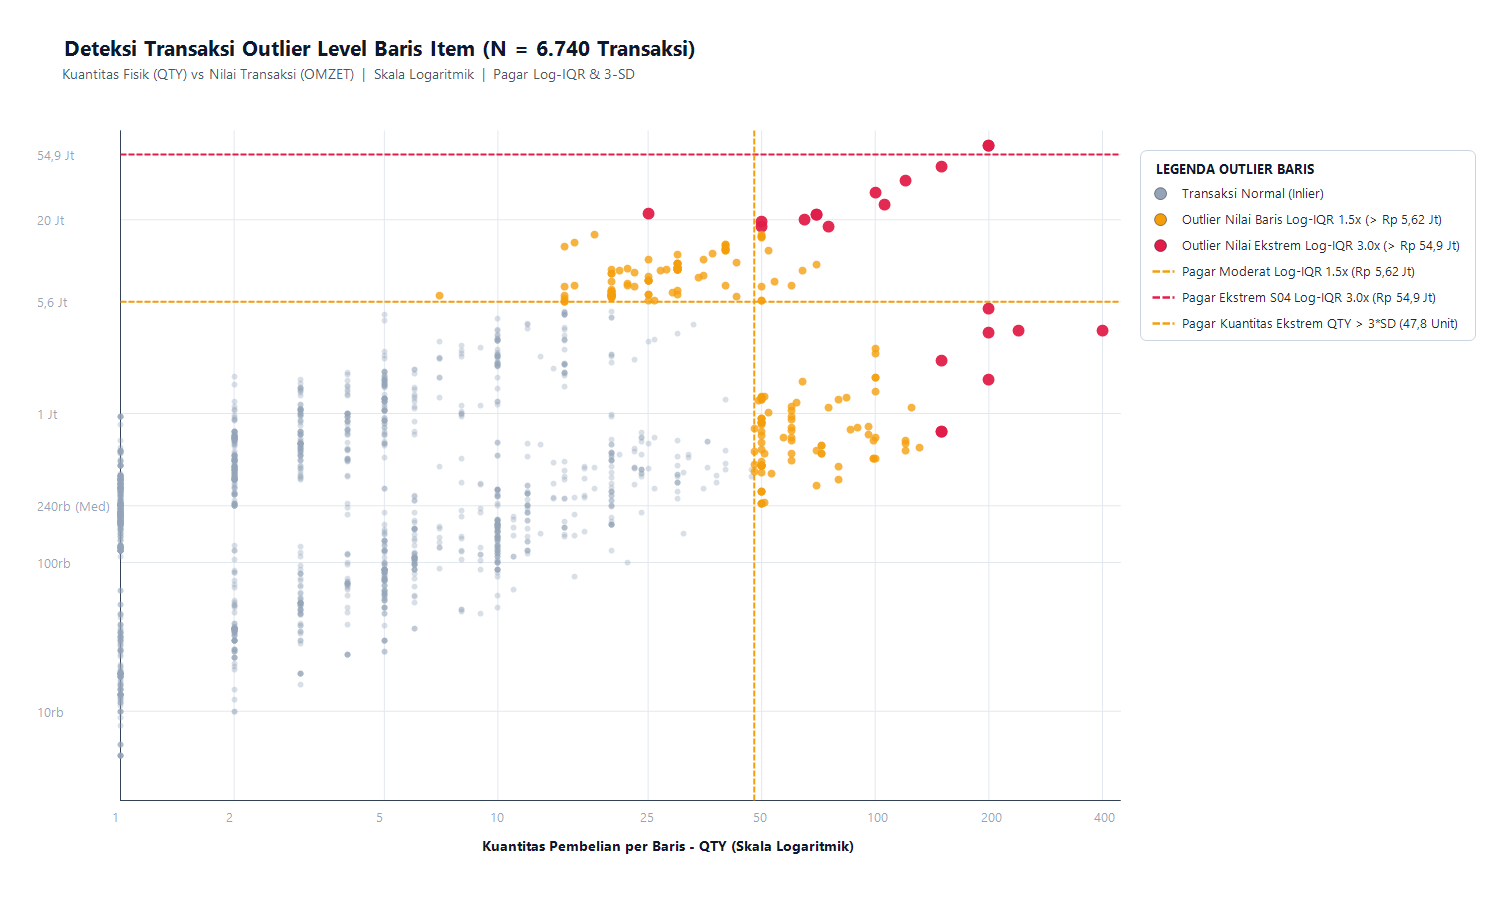

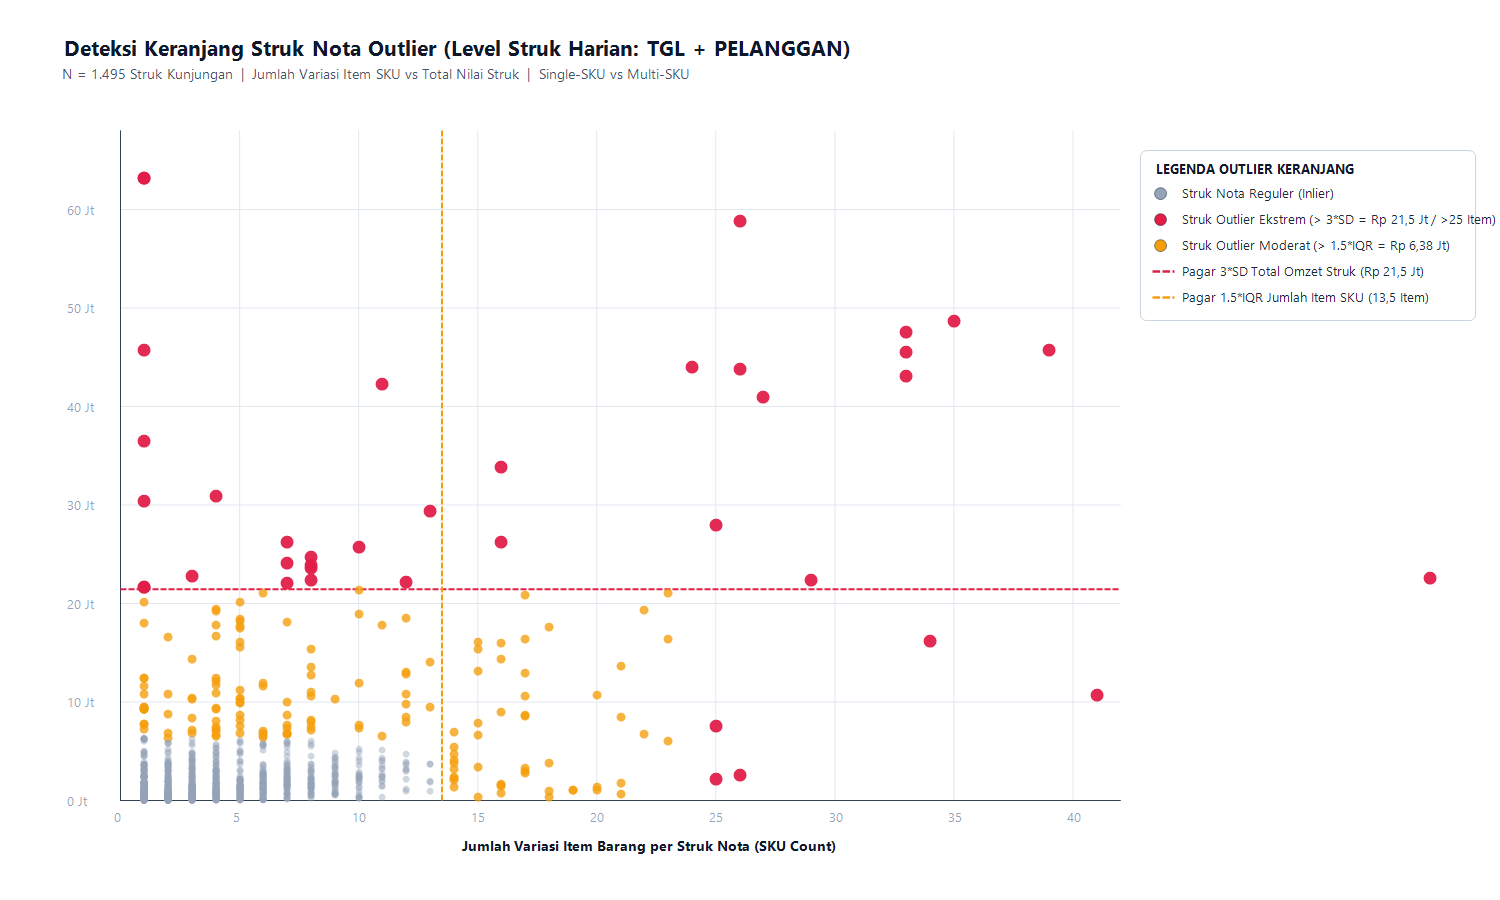

In [5]:
# SISI 3A & 3B: Deteksi Transaksi Outlier Baris Item & Struk Nota
log_omz = np.log10(df_clean['OMZET'])
q1_lg, q3_lg = log_omz.quantile([0.25, 0.75])
iqr_lg = q3_lg - q1_lg
fence_log_15 = 10 ** (q3_lg + 1.5 * iqr_lg)
fence_log_30 = 10 ** (q3_lg + 3.0 * iqr_lg)

print(f'Pagar Log-IQR 1.5x : Rp {fence_log_15:,.0f} -> {(df_clean["OMZET"] > fence_log_15).sum()} baris')
print(f'Pagar Log-IQR 3.0x : Rp {fence_log_30:,.0f} -> {(df_clean["OMZET"] > fence_log_30).sum()} baris ekstrem (S04)')

display(df_clean.sort_values('OMZET', ascending=False)[['TGL', 'PELANGGAN', 'KODE', 'NAMA_BARANG', 'SATUAN', 'QTY', 'HARGA', 'OMZET']].head(10))

# Menampilkan 2 Grafik Raw: Scatter QTY vs OMZET & Keranjang Struk (dengan Legenda Mandiri)
display(Image(filename='slide_assets/outlier_ppt/raw/raw_07_transaksi_scatter_qty_omzet.png'))
display(Image(filename='slide_assets/outlier_ppt/raw/raw_08_transaksi_keranjang_struk.png'))

=== 4 TANGGAL LONJAKAN OMZET HARIAN EKSTREM (T01: Z_Robust > 5.0) ===
Median Omzet Harian = Rp 25,650,400 | MAD = Rp 9,146,182 | Ambang Z_robust > 5 = Rp 93,450,000
=== 1 TRANSAKSI OUTLIER OPERASIONAL HARI MINGGU (T02) ===
Baris #5546 | Minggu, 2020-08-30 | PAK PEPI | OKEY-003 | 1 DUS @ Rp 180,000

Kategori Anomali,Tanggal,Hari,Jumlah Baris,Jumlah Outlet,Total Omzet Harian,Z_Robust Harian,Pendorong Utama / Diagnosis Operasional
T01 (Spike #1),2020-06-26,Friday,118,28,"Rp 188,494,300",+12.01,"Restok serentak ADEK FROZEN (35 item = Rp 48,6 Jt) & FIRDON"
T01 (Spike #2),2020-07-29,Wednesday,118,26,"Rp 163,210,850",+10.15,"Restok menjelang Idul Adha: ADEK FROZEN (26 item = Rp 58,8 Jt)"
T01 (Spike #3),2020-08-18,Tuesday,86,22,"Rp 144,877,550",+8.79,"Borongan ADEK FROZEN (24 item = Rp 43,5 Jt) & ANTON (25 item = Rp 41,0 Jt)"
T01 (Spike #4),2020-08-03,Monday,70,21,"Rp 129,031,350",+7.62,"Dua Mega-Order 1-SKU: PAK SUTARMUJI (Rp 63,2 Jt) + MAS ROHMAT (Rp 45,8 Jt)"
T02 (Sunday Outlier),2020-08-30,Sunday*,1,1,"Rp 180,000",-1.88,PAK PEPI (1 DUS OKEY-003): Toko tutup pada 25 dari 26 hari Minggu!


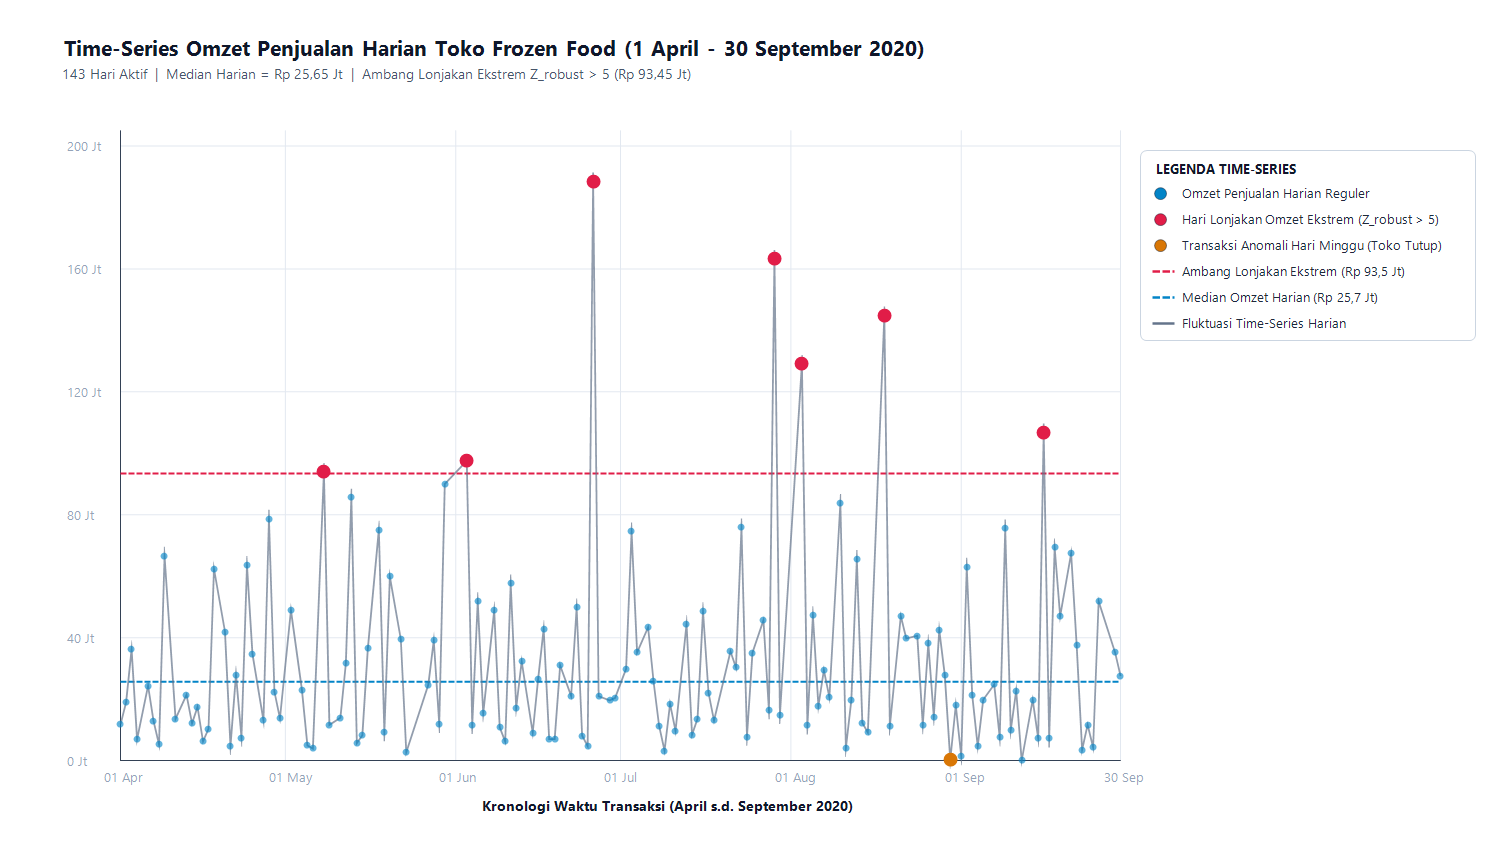

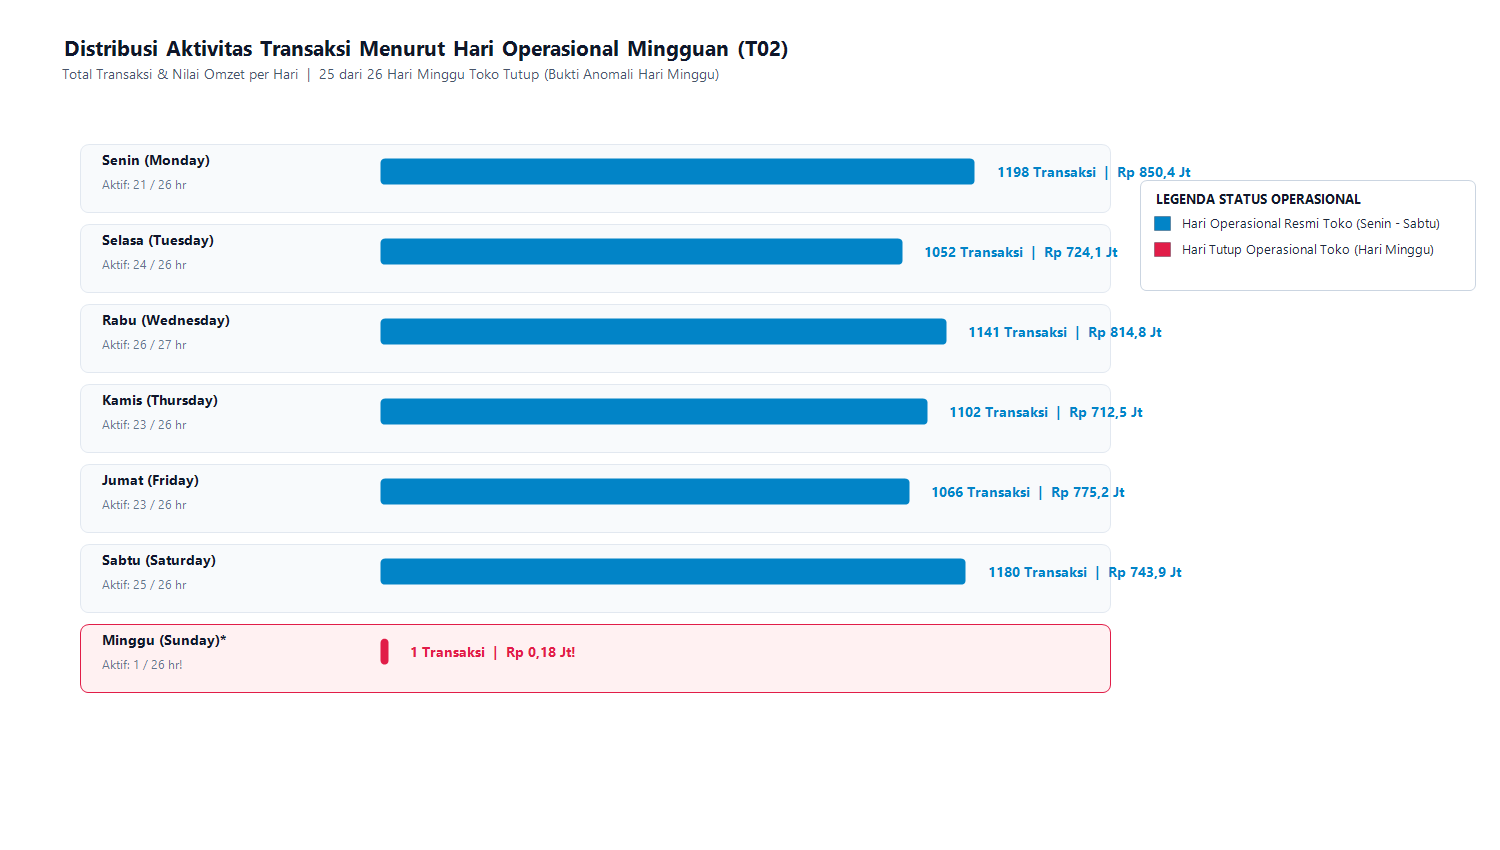

In [6]:
# SISI 3C: Deteksi Outlier Transaksi Temporal & Operasional
daily = df_clean.groupby('TGL').agg(
    Jumlah_Baris=('KODE', 'count'),
    Jumlah_Nota=('PELANGGAN', 'nunique'),
    Total_QTY=('QTY', 'sum'),
    Total_Omzet=('OMZET', 'sum')
).reset_index()

med_day = daily['Total_Omzet'].median()
mad_day = np.median(np.abs(daily['Total_Omzet'] - med_day))
daily['Z_Robust_Harian'] = (daily['Total_Omzet'] - med_day) / (1.4826 * mad_day)

print('=== 4 TANGGAL LONJAKAN OMZET HARIAN EKSTREM (T01: Z_Robust > 5.0) ===')
display(daily[daily['Z_Robust_Harian'] > 5.0].sort_values('Total_Omzet', ascending=False))

print('=== 1 TRANSAKSI OUTLIER OPERASIONAL HARI MINGGU (T02) ===')
display(df_clean[df_clean['TGL'].dt.dayofweek == 6][['TGL', 'PELANGGAN', 'KODE', 'NAMA_BARANG', 'SATUAN', 'QTY', 'HARGA', 'OMZET', 'ATURAN_TERPICU']])

# Menampilkan 2 Grafik Raw: Time-Series Harian & Distribusi Hari Operasional (dengan Legenda Mandiri)
display(Image(filename='slide_assets/outlier_ppt/raw/raw_09_transaksi_timeseries_harian.png'))
display(Image(filename='slide_assets/outlier_ppt/raw/raw_10_transaksi_hari_operasional.png'))

---
## Bagian 4: Katalog Gambar Mandiri (*Raw Graphs*) untuk Kustomisasi Slide PowerPoint

Seluruh gambar di bawah ini telah disimpan di folder `slide_assets/outlier_ppt/raw/` dengan resolusi tinggi (1500 x 850 / 900 px) dengan latar belakang putih bersih dan kotak legenda di sisi kanan, sehingga Anda dapat langsung memasukkannya ke template presentasi PowerPoint kelompok:

| No | File Gambar (*Raw*) | Isi Grafik | Legenda yang Disertakan |
| :---: | :--- | :--- | :--- |
| **1** | `raw_01_frekuensi_aturan_anomali.png` | Bar horizontal jumlah baris aturan anomali & outlier. | 5 kategori warna (Master Data, Transaksi, Error Sistem, Outlier Harga, Variasi Wajar). |
| **2** | `raw_02_pelanggan_boxplot_monetary_aov.png` | 1D Boxplot & strip plot sebaran Total Belanja ($M$) dan AOV ($M/F$) pelanggan. | Inlier, Outlier 1.5*IQR, Outlier 3*SD, Rentang IQR [Q1, Q3], Garis Median. |
| **3** | `raw_03_pelanggan_scatter_convexhull.png` | 2D Scatter plot Frequency vs Monetary dengan poligon pembungkus Convex Hull. | Inlier, Whale ($p_1$), One-Shot Bulk ($p_2$), Convex Hull Boundary, Pagar IQR. |
| **4** | `raw_04_pelanggan_lof_density.png` | 2D Scatter Log Frequency vs Log AOV dengan radius cincin = skor LOF. | Inlier (LOF ~ 1), Outlier Kritis (LOF > 1.35), Outlier Moderat, Zona Klaster Utama. |
| **5** | `raw_05_harga_diverging_sku_median.png` | Diverging lollipop chart deviasi harga satuan (%) terhadap median SKU+Satuan. | Outlier Terlalu Murah/Mahal (|Dev| > 30%), Tier Grosir (|Z| > 5), Zona Wajar [-30%, +30%]. |
| **6** | `raw_06_harga_distribusi_satuan_kemasan.png` | Boxplot perbandingan harga barang antar 7 satuan kemasan (DUS s.d. PCS). | Rentang IQR, Median Kemasan, Pagar Atas, Outlier SKU Premium. |
| **7** | `raw_07_transaksi_scatter_qty_omzet.png` | 2D Scatter kuantitas fisik (QTY) vs nilai transaksi (OMZET) level baris item. | Inlier, Outlier Log-IQR 1.5x (Rp 5,6 Jt), Outlier Ekstrem S04 (Rp 54,9 Jt), Pagar QTY 3-SD. |
| **8** | `raw_08_transaksi_keranjang_struk.png` | 2D Scatter variasi SKU vs total belanja level keranjang struk nota harian. | Struk Reguler, Struk Outlier Ekstrem (> Rp 21,5 Jt), Outlier Moderat, Pagar 3-SD. |
| **9** | `raw_09_transaksi_timeseries_harian.png` | Time-series grafik garis omzet harian toko frozen food (April - September 2020). | Omzet Reguler, 4 Hari Lonjakan Ekstrem, Transaksi Hari Minggu, Ambang Z > 5, Median. |
| **10**| `raw_10_transaksi_hari_operasional.png` | Bar chart volume transaksi & nilai omzet per hari kerja (Senin s.d. Minggu). | Hari Operasional Normal (Senin - Sabtu), Hari Tutup Operasional (Hari Minggu). |